### Daniel Barella
9/10/25

# Day 8 – Data Visualization Basics
## ✅ Goals

1. Learn the basics of Matplotlib and Seaborn

2. Plot your first charts: line plots, bar charts, histograms, scatter plots

3. Use Titanic dataset to visualize survival patterns

## 🔧 Step-by-Step Instructions
### 1. Install Seaborn (if not already installed)

In your notebook cell, run:

In [1]:
!pip install seaborn


### 2. Import Libraries

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


### 3. Load Titanic Data

Use the same dataset you worked with in Day 5–7:

In [4]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(url)

# Inspect
titanic.head()
titanic.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


### 4. Basic Matplotlib Examples

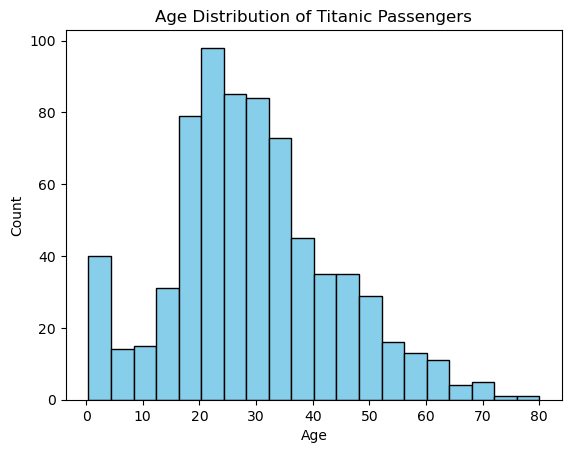

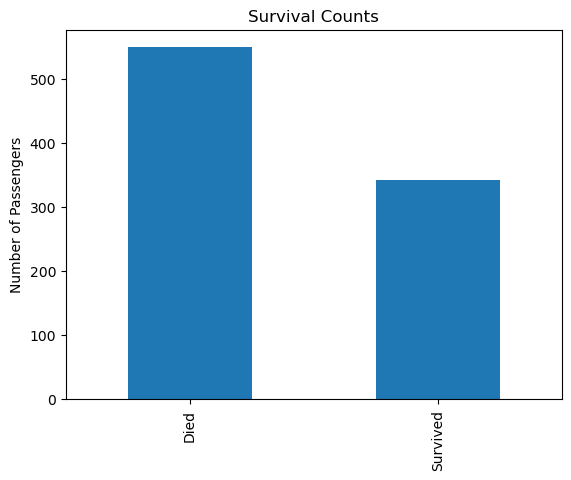

In [5]:
# Histogram of Age
plt.hist(titanic["Age"].dropna(), bins=20, color="skyblue", edgecolor="black")
plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

# Bar chart of Survival Counts
titanic["Survived"].value_counts().plot(kind="bar")
plt.title("Survival Counts")
plt.xticks([0, 1], ["Died", "Survived"])
plt.ylabel("Number of Passengers")
plt.show()



### 5. Seaborn Examples

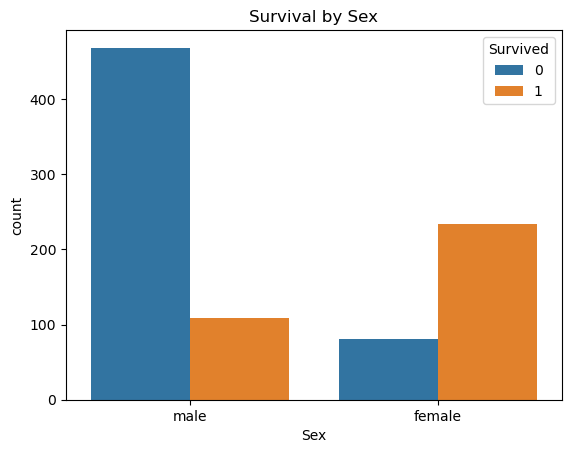

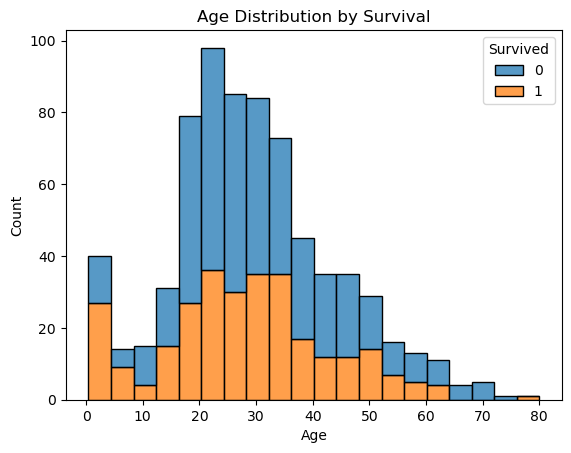

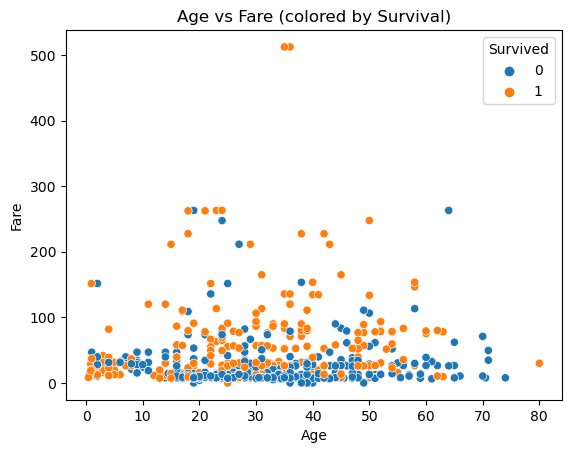

In [6]:
# Countplot: Survival by Sex
sns.countplot(x="Sex", hue="Survived", data=titanic)
plt.title("Survival by Sex")
plt.show()

# Histogram: Age Distribution by Survival
sns.histplot(data=titanic, x="Age", hue="Survived", multiple="stack")
plt.title("Age Distribution by Survival")
plt.show()

# Scatter: Age vs Fare
sns.scatterplot(x="Age", y="Fare", hue="Survived", data=titanic)
plt.title("Age vs Fare (colored by Survival)")
plt.show()


### 6. Mini Project

Visualize 3 survival patterns using different plot types:

1. Survival by Passenger Class (bar plot)

2. Age distribution of survivors vs non-survivors (histogram)

3. Fare vs Age with survival hue (scatter plot)

### 1. Survival by Passenger Class (bar plot)


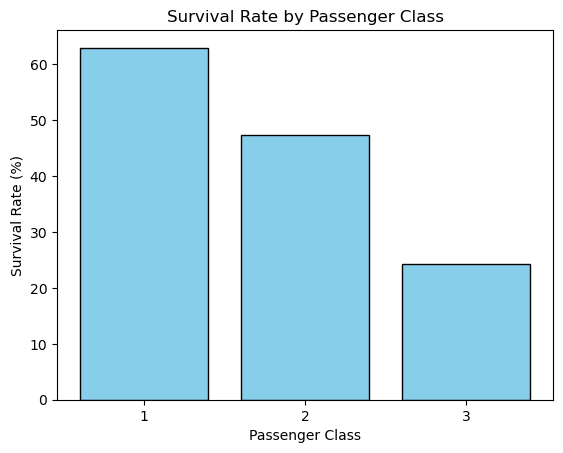

In [7]:

# Calculate survival rate by class
survival_by_class = titanic.groupby("Pclass")["Survived"].mean() * 100

# Plot
plt.bar(survival_by_class.index, survival_by_class.values, color="skyblue", edgecolor="black")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.title("Survival Rate by Passenger Class")
plt.xticks([1, 2, 3])  # class labels
plt.show()

### 2. Age distribution of survivors vs non-survivors (histogram)


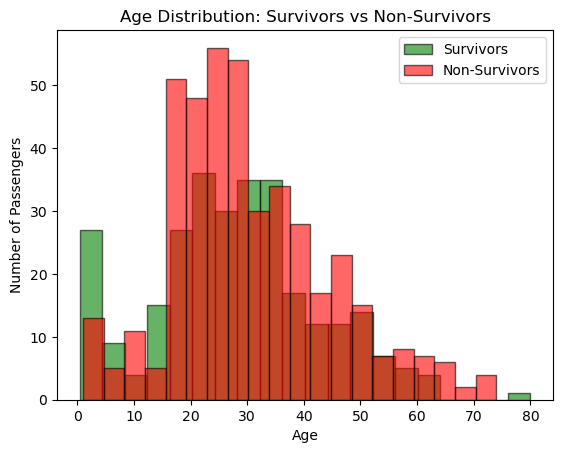

In [8]:
# Drop missing ages
titanic = titanic.dropna(subset=["Age"])

# Separate survivors and non-survivors
survivors = titanic[titanic["Survived"] == 1]["Age"]
nonsurvivors = titanic[titanic["Survived"] == 0]["Age"]

# Plot histogram
plt.hist(survivors, bins=20, alpha=0.6, label="Survivors", color="green", edgecolor="black")
plt.hist(nonsurvivors, bins=20, alpha=0.6, label="Non-Survivors", color="red", edgecolor="black")

plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.title("Age Distribution: Survivors vs Non-Survivors")
plt.legend()
plt.show()

### 3. Fare vs Age with survival hue (scatter plot)

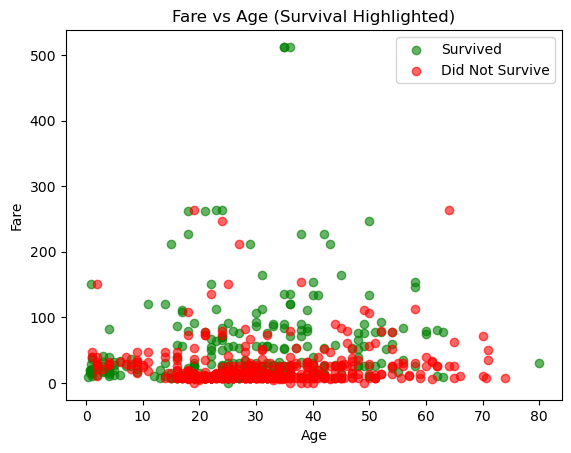

In [9]:
# Drop rows with missing Age or Fare
titanic = titanic.dropna(subset=["Age", "Fare"])

# Scatter plot: Fare vs Age, colored by survival
plt.scatter(
    titanic[titanic["Survived"] == 1]["Age"], 
    titanic[titanic["Survived"] == 1]["Fare"], 
    color="green", alpha=0.6, label="Survived"
)
plt.scatter(
    titanic[titanic["Survived"] == 0]["Age"], 
    titanic[titanic["Survived"] == 0]["Fare"], 
    color="red", alpha=0.6, label="Did Not Survive"
)

plt.xlabel("Age")
plt.ylabel("Fare")
plt.title("Fare vs Age (Survival Highlighted)")
plt.legend()
plt.show()